# Simulating an M+1 experiment

To begin with the M+1 code, it is helpful to check if a proposed experiment can recover the site-specific values you care about. This tutorial shows how to do this, using alanine from Weiss et al. 2023 as a model. 

Specifically, we:

1. Build a model of alanine.
2. Examine its predicted spectrum.
3. Simulate a full sample/standard comparison, using user-defined input values for both sample and standard.
4. Apply the M+1 algorithm to these data to recover the site-specific values.

This will demonstrate both which sites are constrained and how precisely they are constrained. 

The example follows the alanine measurements of Weiss et al. (2023); the method is described in
Csernica and Eiler (2023). See the [README](https://github.com/Csernica/isotomics#citation) for
full citations.

In [1]:
from importlib import resources

import pandas as pd
import matplotlib.pyplot as plt

from isotomics import readCSVAndSimulate as sim
from isotomics import spectrumVis

# Example inputs bundled with the package
DATA = resources.files("isotomics") / "input_data"
MOLECULE_INPUT_PATH = str(DATA / "Example_Molecule_Input.csv")

## 1. Describe the molecule

To define a molecule, we construct a .csv file with one row per **site** where a site is a group of atoms of the same element which are treated as isotopically equivalent (see Csernica and Eiler 2023). For example, three methyl hydrogens may be a site as they are indistinguishable. We can also treat atoms which are (in principle) distinguishable, such as alpha and beta carbons, as part of the same site when our experimental design cannot distinguish these. 

The .csv file also includes the number of atoms in a site, and information about how that site is sampled upon fragmentation. This is done by providing whether a site is retained ('1') or lost ('0') upon fragmentation. Importantly, **there is no way for a site to be partially retained or lost**, which may force us to split atoms which we would intuitively combine. For example, if there is a set of 3 methyl hydrogens, and 2 of these are lost but one retained to form a given fragment, we cannot input 1/3 to a methyl site with 3 hydrogens; we must instead define two sites (H_methyl_retained and H_methyl_lost, for example), and then give them values of '1' and '0' for the corresponding fragment.

You will have to trust that this unintuitive treatment has some nice benefits in calculation elsewhere. 

Finally, we have a 'full' fragment; in a certain sense this is not a 'fragment' of the molecule, but mathematically it is equivalent (it is a special case of a 'fragment' with all sites retained) and so we use the same nomenclature. This should only be included when we observe the intact molecule. 

:::{note}
**Fragments formed by more than one pathway.** Sometimes the same fragment ion forms by several
pathways that retain different sites. In that case, give the fragment one column per pathway
(`Fragment 82_01`, `Fragment 82_02`, …) and add a final row named `Relative Contribution` giving
the share of the fragment formed by each pathway. Each pathway becomes a *subgeometry* of the
fragment. Each fragment in the alanine example forms by a single pathway, so its .csv has neither.
See *Fragments formed by more than one pathway* at the end of this tutorial for a full example.
:::

The alanine .csv can be viewed at "isotomics\input_data\Example_Molecule_Input.csv". 

In [2]:
molecule = pd.read_csv(MOLECULE_INPUT_PATH, index_col="Site Names")
molecule[["Element", "Number Atoms", "Fragment full", "Fragment 44"]]

,Element,Number Atoms,Fragment full,Fragment 44
Site Names,,,,
Calphabeta,C,2,1,1
Ccarboxyl,C,1,1,0
Ocarboxyl,O,2,1,0
Namine,N,1,1,1
Hretained,H,6,1,1
Hlost,H,2,1,0


Here alanine is split into six sites. The `44` fragment retains the α and β carbons, the amine
nitrogen and six of the hydrogens, but loses the carboxyl group and two hydrogens. Because
fragment 44 sees some sites but not others, comparing it with the full molecule is what lets
the solver separate, for example, the carboxyl carbon from the other two carbons.

## 2. Predict the spectrum of the standard

With our csv thus defined, we next define a set of delta values, read the csv with these delta values to initialize a molecule with a specific isotopic structure  using `moleculeFromCsv`, and simulate a measurement using `simulateMeasurement`. This is an ideal measurement with no
instrument fractionation. Site δ values are always
given in the same order as the CSV rows.

In [3]:
STD_DELTAS = [-11.9, -9.95, 0, 0, 0, 0]  # Calphabeta, Ccarboxyl, Ocarboxyl, Namine, Hretained, Hlost

initializedMolecule = sim.moleculeFromCsv(MOLECULE_INPUT_PATH, deltas=STD_DELTAS)
predictedMeasurement, MNDict, _ = sim.simulateMeasurement(initializedMolecule, massThreshold=5)

`initializedMolecule` contains the basic information about the molecule--the table we just entered as a csv (molecularDataFrame), as well as various depictions of the fragments. These include both a "site" description of fragmentation, showing which sites are retained and lost, and an "atom" description, which expands each site to its constituent atoms and then tracks fragmentation. 

In [4]:
initializedMolecule

{'molecularDataFrame':            IDS  Number  Fragment full Fragment 44  deltas
 Calphabeta   C       2              1           1  -11.90
 Ccarboxyl    C       1              1           x   -9.95
 Ocarboxyl    O       2              1           x    0.00
 Namine       N       1              1           1    0.00
 Hretained    H       6              1           1    0.00
 Hlost        H       2              1           x    0.00,
 'expandedFrags': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
  [1, 1, 'x', 'x', 'x', 1, 1, 1, 1, 1, 1, 1, 'x', 'x']],
 'fragSubgeometryKeys': ['full_01', '44_01'],
 'fragmentationDictionary': {'full': {'01': {'subgeometry': [1, 1, 1, 1, 1, 1],
    'relCont': 1}},
  '44': {'01': {'subgeometry': [1, 'x', 'x', 1, 1, 'x'], 'relCont': 1}}}}

It is a dictionary with four entries:

- `molecularDataFrame`: the CSV as a table, with columns renamed for the code (`IDS` for the
  element, `Number` for the number of atoms), lost sites written as `x` instead of `0`, and a
  `deltas` column holding the δ values you passed in.
- `fragmentationDictionary`: for each fragment, its **site** depiction (one entry per site;
  `1` retained, `x` lost). A fragment can form by more than one pathway; each pathway is a
  *subgeometry* (`01`, `02`, …) with a `relCont` giving its relative contribution. Each fragment
  here has a single subgeometry.
- `expandedFrags`: the **atom** depiction of each subgeometry, with one entry per atom. Alanine's
  six sites hold 14 atoms, so each vector has 14 entries.
- `fragSubgeometryKeys`: names for each subgeometry (`full_01`, `44_01`), in the same order as
  `expandedFrags`.

In [5]:
initializedMolecule["fragmentationDictionary"]

{'full': {'01': {'subgeometry': [1, 1, 1, 1, 1, 1], 'relCont': 1}},
 '44': {'01': {'subgeometry': [1, 'x', 'x', 1, 1, 'x'], 'relCont': 1}}}

`predictedMeasurement` holds the predicted observations. It has one entry per mass selection
(`M0` to `M5` here, set by `massThreshold`) plus `U Values`:

In [6]:
list(predictedMeasurement)

['M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'U Values']

Within a mass selection there is one entry per fragment, and within that one entry per
**peak**, named by the substitution it carries (`13C`, `15N`, `2H`, …). For the M+1 measurement
of fragment 44:

In [7]:
pd.DataFrame(predictedMeasurement["M1"]["44"]).T

,Abs. Abundance,Rel. Abundance,Combined Rel. Abundance,Adj. Rel. Abundance
Unsub,0.011633,0.312530,0.312530,0.312530
2H,0.000896,0.024059,0.024059,0.024059
15N,0.003522,0.094634,0.094634,0.094634
13C,0.021171,0.568778,0.568778,0.568778


Note the `Unsub` peak. It contains M+1 molecules whose rare isotope was on a site that fragment
44 loses (the carboxyl group or the lost hydrogens), so the fragment ion carries no
substitution. How the M+1 population splits between peaks like this, fragment by fragment, is
what the solver uses to place each substitution on a site.

Each peak has four abundances, which apply successive steps of the measurement model:

- `Abs. Abundance`: the fraction of all molecules that end up in this peak.
- `Rel. Abundance`: normalized so the peaks of this fragment sum to 1. These are the
  **M+N relative abundances** the method works with.
- `Combined Rel. Abundance`: after merging peaks the instrument cannot resolve (the
  `unresolvedDict` option; nothing is merged here).
- `Adj. Rel. Abundance`: after removing peaks you will not observe (`omitMeasurements`, or below
  `abundanceThreshold`) and renormalizing. This is what the solver uses.

`U Values` gives molecular-average ratios: for each substitution, the abundance of all
isotopologues carrying it relative to the unsubstituted molecule. ¹³C/Unsub is the U value used
to anchor the site-specific results:

In [8]:
pd.Series(predictedMeasurement["U Values"])[["13C", "15N", "17O", "18O", "2H"]]

13C    0.033163
15N    0.003676
17O    0.000760
18O    0.004010
2H     0.001246
dtype: float64

`MNDict` tracks the **isotopologues** behind those peaks. For each mass selection it lists every
isotopologue, keyed by a string with one character per atom (in the order of the sites, so 14
characters for alanine), along with its concentration and how it fragments:

In [9]:
pd.DataFrame(MNDict["M1"]).T

,Number,Full,Conc,Mass,Subs,Stochastic U,full_01 Identity,full_01 Subs,44_01 Identity,44_01 Subs
00000000000001,2,"(0, 0)0(0, 0)0(0, 0, 0, 0, 0, 0)(0, 1)",0.000299,1,2H,0.000312,00000000000001,2H,00xxx0000000xx,Unsub
00000000000100,6,"(0, 0)0(0, 0)0(0, 0, 0, 0, 0, 1)(0, 0)",0.000896,1,2H,0.000935,00000000000100,2H,00xxx0000001xx,2H
00000100000000,1,"(0, 0)0(0, 0)1(0, 0, 0, 0, 0, 0)(0, 0)",0.003522,1,15N,0.003676,00000100000000,15N,00xxx1000000xx,15N
00001000000000,2,"(0, 0)0(0, 1)0(0, 0, 0, 0, 0, 0)(0, 0)",0.000728,1,17O,0.00076,00001000000000,17O,00xxx0000000xx,Unsub
00100000000000,1,"(0, 0)1(0, 0)0(0, 0, 0, 0, 0, 0)(0, 0)",0.010606,1,13C,0.011069,00100000000000,13C,00xxx0000000xx,Unsub
01000000000000,2,"(0, 1)0(0, 0)0(0, 0, 0, 0, 0, 0)(0, 0)",0.021171,1,13C,0.022094,01000000000000,13C,01xxx0000000xx,13C


- `Number`: how many equivalent isotopologues this row stands for (e.g. a ¹³C on either of the
  two α/β carbons).
- `Full`: the same isotopologue written site by site, with one group per site.
- `Conc`: concentration, as a fraction of all molecules.
- `Mass`: its nominal mass shift (1 for M+1).
- `Subs`: the substitution it carries.
- `Stochastic U`: its abundance relative to the unsubstituted molecule.
- `<fragment> Identity` and `<fragment> Subs`: the fragment ion it forms (`x` marks lost atoms)
  and the substitution that ion carries, i.e. which peak it contributes to.

The full-molecule spectrum shows the unsubstituted peak and every isotopologue up to M+5 (set by massThreshold, above)

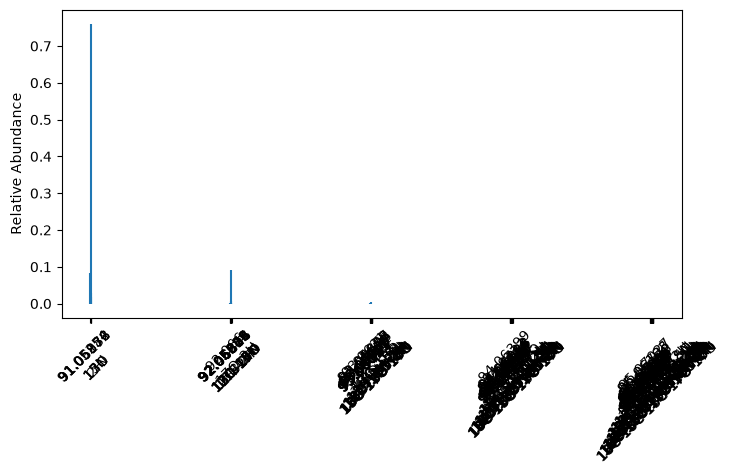

In [10]:
spectrumVis.fullSpectrumVis(
    predictedMeasurement["U Values"],
    initializedMolecule["molecularDataFrame"],
    figsize=(8, 4),
)

And the M+1 population of fragment 44: after selecting the M+1 ions of the molecule, how they
distribute among the unsubstituted, ¹³C, ¹⁵N and ²H peaks of the fragment.

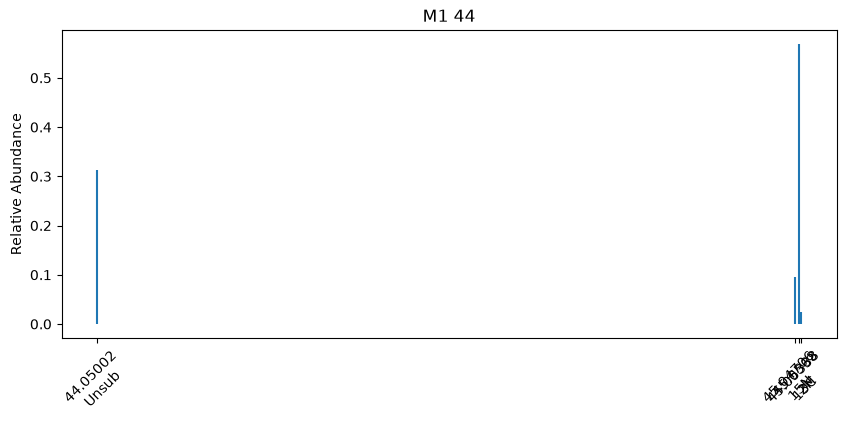

In [11]:
spectrumVis.MNSpectrumVis(
    initializedMolecule["molecularDataFrame"], "44", predictedMeasurement, "M1", MNDict,
)

:::{tip}
Pass `outputIsotopologs=True` to either plotting function to also write an `isotopologs.tsv`
listing these peaks, which you can use to set up data processing in IsoX.
:::

## 3. Simulate a sample/standard comparison

Measurements are always made by comparing a sample with a standard. To simulate one you need
**three** sets of δ values, which is the part new users most often find confusing:

- `STD_DELTAS`: the *true* composition of the standard. The simulation uses this to generate the
  standard's measurement.
- `SMP_DELTAS`: the *true* composition of the sample.
- `STANDARD_DELTA_APPROX`: what *you believe* the standard's composition is. The solver only ever
  sees this one, exactly as it would with real data, where the true values are unknown. Here
  the carbon sites are known externally and the rest are set to 0.

Here the guess for the standard is 1 ‰ off in both carbon sites, and the sample is strongly
enriched in the carboxyl carbon.

In [12]:
STD_DELTAS = [-12.9, -10.95, 0, 0, 0, 0]
SMP_DELTAS = [-12.656, 21.685, 0, 0, 0, 0]
STANDARD_DELTA_APPROX = [-11.9, -9.95, 0, 0, 0, 0]

Next, describe how good the measurement will be. The error file gives the expected relative
error of each observed peak, plus the error on the molecular-average measurement. Errors are
given as fractions throughout `isotomics`, so 0.001 means 1 ‰:

In [13]:
ERROR_PATH = str(DATA / "Alanine Experimental Errors.csv")
print((DATA / "Alanine Experimental Errors.csv").read_text(encoding="utf-8-sig"))

Molecular Average,Relative Error
13C/Unsub,0.0001
Fragment full,M+1 Relative Abundance Error
2H,0.005
15N,0.002
13C,0.001
17O,0.005
Fragment 44,M+1 Relative Abundance Error
Unsub,0.001
2H,0.005
13C,0.001
15N,0.002



A few more choices describe the experiment:

- `OMIT_MEASUREMENTS` drops ion beams you will not observe. ¹⁷O is often unresolved, so it is
  removed from the full molecule here.
- `calcFF` and `ffstd` add random instrumental fractionation to every ion beam (here σ = 1 %),
  applied identically to sample and standard, as in a real sample/standard comparison.
- `UValueList` sets the molecular-average ratio (here ¹³C/Unsub) that converts M+1 relative
  abundances into site-specific values. Its error (0.1 ‰) comes from the error file.

Then `simulateSmpStd` simulates both measurements, solves them with the M+1 Monte Carlo routine
and plots the recovered sample composition relative to the standard.

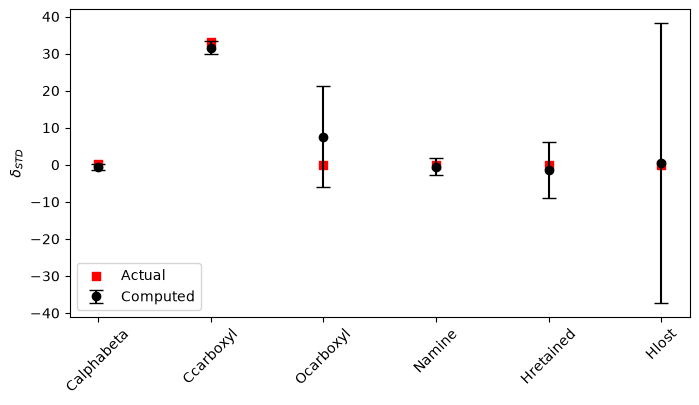

In [14]:
simulationOutput = sim.simulateSmpStd(
    MOLECULE_INPUT_PATH,
    STD_DELTAS,
    SMP_DELTAS,
    STANDARD_DELTA_APPROX,
    UValueList=["13C"],
    omitMeasurements={"M1": {"full": ["17O"]}},
    calcFF=True,
    ffstd=0.01,
    errorPath=ERROR_PATH,
    resultsFileName="molecular_model_output.csv",
)

In [15]:
summary = simulationOutput[["Relative Deltas", "Relative Deltas Error", "CRF Deltas", "CRF Deltas Error"]].copy()
# The true sample-vs-standard values the simulation was built from, for comparison
summary.insert(0, "True Relative Deltas",
               [((1000 + smp) / (1000 + std) - 1) * 1000 for smp, std in zip(SMP_DELTAS, STD_DELTAS)])
summary.round(2)

,True Relative Deltas,Relative Deltas,Relative Deltas Error,CRF Deltas,CRF Deltas Error
Calphabeta,0.25,-0.58,0.89,-12.47,0.88
Ccarboxyl,33.00,31.60,1.75,21.34,1.74
Ocarboxyl,0.00,7.56,13.61,7.56,13.61
Namine,0.00,-0.48,2.31,-0.48,2.31
Hretained,0.00,-1.42,7.63,-1.42,7.63
Hlost,0.00,0.43,37.77,0.43,37.77


`simulationOutput` is a table with one row per site. Besides the δ values above, it keeps the
intermediate steps of the M+1 algorithm, which show how the result is built:

In [16]:
simulationOutput[["Number", "M1 M+N Relative Abundance", "UM1", "Calc U Values"]].round(5)

,Number,M1 M+N Relative Abundance,UM1,Calc U Values
Calphabeta,2,0.56352,0.03918,0.02208
Ccarboxyl,1,0.29140,0.03918,0.01142
Ocarboxyl,2,0.01954,0.03918,0.00077
Namine,1,0.09377,0.03918,0.00367
Hretained,6,0.02382,0.03918,0.00093
Hlost,2,0.00795,0.03918,0.00031


- `M1 M+N Relative Abundance`: the solved composition of the M+1 population, i.e. the fraction
  of singly substituted molecules whose substitution sits on each site. These sum to 1.
- `UM1`: the abundance of all M+1 isotopologues relative to the unsubstituted molecule, derived
  from the molecular-average measurement (here ¹³C/Unsub, known to 0.1 ‰) and the ¹³C share of
  the solved M+1 composition.
- `Calc U Values`: their product, the U value of each site. Dividing by the number of atoms
  gives each site's isotope ratio, and hence its δ value.

Each column has a matching `Error` column from the Monte Carlo.

## 4. Interpreting the result

- **Relative Deltas** are the sample's site-specific values relative to the standard.
- **CRF Deltas** are the same values expressed in the reference frame of
  `STANDARD_DELTA_APPROX`, so they are only as accurate as your knowledge of the standard.
- The **errors** come from the Monte Carlo and show how well this experiment constrains each
  site.

The recovered relative values agree with the true ones within their errors, and the carbon
sites are constrained to within 1–2 ‰. Sites that only the full molecule constrains, such as the
carboxyl oxygen and the lost hydrogens, are much less certain. This is
what the simulation is for: to try adding fragments, improving the error on a peak, or dropping
a peak you might not resolve, and see what each change does to the answer before going to the
instrument.

## Using your own molecule

1. Write a molecule CSV in the format above for your compound and the fragments you plan to
   observe.
2. Write an error CSV with the precision you expect for each peak.
3. Rerun this notebook with your paths and δ values.

## Fragments formed by more than one pathway

Sometimes the same fragment ion forms by several pathways that keep different sites. Give each
pathway its own column, named `Fragment <name>_01`, `Fragment <name>_02`, and so on, and add a
final row named `Relative Contribution` giving the share of the fragment formed by each
pathway. The shares must sum to 1 for each fragment. Fragments with a single column default to
1, so their cells in that row can be left empty:

```text
Site Names,Element,Number Atoms,Fragment full,Fragment 82_01,Fragment 82_02
C1,C,1,1,1,0
C2,C,1,1,0,1
O1,O,1,1,1,1
Relative Contribution,,,,0.4,0.6
```

Each pathway becomes a subgeometry of the fragment in `fragmentationDictionary` (`82` → `01`,
`02`, with their `relCont`). The simulation adds the pathways in these proportions, and the
solver accounts for them when assigning substitutions to sites. The experimental data for the
fragment still goes in a single folder, named `82`.

The next tutorial, {doc}`m1_experimental_workflow`, solves real measurements of this alanine
system.